<a href="https://colab.research.google.com/github/a01841264-cloud/TC5053-ciencia-datos/blob/main/Actividad4EDA_A01841264.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Roberto Mendoza Monreal
*   MATRÍCULA: A01841264

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [29]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [30]:
loan_df = pd.read_csv('/content/personal_loan.csv', index_col='ID')
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [31]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [32]:
n_inicial = len(loan_df)
display(loan_df.describe())
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [33]:
loan_df = loan_df[loan_df['Age'] <= 100]

**Respuesta:** Se encontraron 3 registros con edad mayor a 100 años (123, 144 y 130). Se eliminaron por no ser plausibles: superan la edad máxima humana registrada y, además, su experiencia laboral (39, 6 y 7 años) es inconsistente con esas edades, lo que indica errores de captura.

In [34]:
invalidos = ((loan_df['Experience'] < 0) |
             (loan_df['Family'] < 1) |
             (~loan_df['Education'].isin([1, 2, 3])) |
             (loan_df['ZIP Code'] < 10000))
loan_df[invalidos]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.50,3.0,0,0,No,0,Yes,Yes
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
347,25,0,43,94305,2,1.60,7.3,0,0,Yes,Yes,1,Yes
384,51,25,21,9307,4,0.60,3.0,0,No,0,0,1,Yes
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0


In [35]:
loan_df = loan_df[~invalidos]
eliminados = n_inicial - len(loan_df)
eliminados, round(eliminados / n_inicial * 100, 2)

(60, 1.19)

**Respuesta:** Además de las edades imposibles, se eliminaron 57 registros con valores inválidos:

* **Experience negativa (53 registros):** los años de experiencia laboral no pueden ser negativos. Casi todos corresponden a clientes de 23 a 28 años, lo que sugiere un error de captura del signo; al no poder conocer el valor real, se eliminaron.
* **Family menor a 1 (2 registros, valores −1 y −3):** el número de miembros de la familia debe ser al menos 1 (el propio cliente).
* **Education = 7.3 (1 registro):** según la descripción, solo puede tomar los valores 1, 2 o 3.
* **ZIP Code de 4 dígitos (1 registro, 9307):** los códigos postales de EE. UU. tienen 5 dígitos, y todos los demás registros pertenecen a California (empiezan con 9).

Las variables `Income`, `CCAvg` y `Mortgage` no presentaron valores inválidos.

**En total se eliminaron 60 registros (3 por edad + 57 por valores inválidos), que representan el 1.19% del dataframe inicial (5,037 registros).**

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [36]:
display(loan_df.describe(include='object'))
for col in loan_df.select_dtypes('object').columns:
    display(loan_df[col].value_counts())

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


,count
Personal Loan,
0,3475
No,1017
Yes,368
1,117


,count
Securities Account,
No,2693
0,1765
Yes,390
1,129


,count
CD Account,
No,2462
0,2212
1,163
Yes,140


,count
Online,
Yes,1700
No,1628
1,1275
0,374


,count
CreditCard,
0,2628
Yes,907
No,885
1,557


In [37]:
binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
loan_df[binarias] = loan_df[binarias].replace({'Yes': '1', 'No': '0'})
for col in binarias:
    display(loan_df[col].value_counts())

,count
Personal Loan,
0,4492
1,485


,count
Securities Account,
0,4458
1,519


,count
CD Account,
0,4674
1,303


,count
Online,
1,2975
0,2002


,count
CreditCard,
0,3513
1,1464


**Respuesta:** Las 5 columnas de texto (`Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`) presentaban 4 valores únicos cada una (`0`, `1`, `No`, `Yes`), aunque son variables binarias. Esto se debe a que la misma información estaba registrada en dos formatos distintos. Para unificarlas de acuerdo con la descripción de las variables (1 = sí, 0 = no), se reemplazó `Yes` por `1` y `No` por `0`. Después del cambio, cada columna tiene únicamente dos categorías.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [38]:
print(loan_df.duplicated().sum())
loan_df = loan_df.drop_duplicates().reset_index(drop=True)
loan_df.shape

36


(4941, 13)

**Respuesta:** Se encontraron 36 registros duplicados (filas idénticas en todas sus columnas), que se eliminaron con `drop_duplicates()`. Varios de ellos solo se volvieron detectables después de unificar los formatos de las variables binarias en el ejercicio anterior. Finalmente, se reinició el índice con `reset_index(drop=True)` para obtener una secuencia continua de 0 a 4,940. El dataframe quedó con 4,941 registros y 13 columnas.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [39]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str)
loan_df['Education'] = pd.Categorical(loan_df['Education'].astype(int), categories=[1, 2, 3], ordered=True)
loan_df[binarias] = loan_df[binarias].astype('category')

num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()
print(num_cols)
print(cat_cols)
loan_df.dtypes

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


**Respuesta:** Se ajustaron los tipos de datos según la naturaleza estadística de cada variable:

* ZIP Code → `object`: aunque contiene números, es una variable nominal; sus valores identifican ubicaciones y no tiene sentido realizar operaciones aritméticas con ellos.
* Education → `category` ordenada (1 < 2 < 3):es una variable ordinal; sus niveles tienen un orden (graduado, universitario, posgrado), pero no representan cantidades.
* Personal Loan, Securities Account, CD Account, Online y CreditCard → `category`: son variables binarias con solo dos categorías (0 = no, 1 = sí).

Como resultado, `num_cols` contiene 6 variables numéricas (Age, Experience, Income, Family, CCAvg y Mortgage) y `cat_cols` contiene 7 variables categóricas.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [40]:
estadisticas = loan_df[num_cols].describe().T
estadisticas['skew'] = loan_df[num_cols].skew()
estadisticas['kurtosis'] = loan_df[num_cols].kurt()
estadisticas.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.56,11.32,24.0,36.0,46.0,55.0,67.0,-0.02,-1.16
Experience,4941.0,20.34,11.31,0.0,11.0,20.0,30.0,43.0,-0.02,-1.13
Income,4941.0,73.83,46.11,8.0,39.0,64.0,98.0,224.0,0.84,-0.05
Family,4941.0,2.39,1.15,1.0,1.0,2.0,3.0,4.0,0.16,-1.40
CCAvg,4941.0,1.94,1.75,0.0,0.7,1.5,2.6,10.0,1.59,2.64
Mortgage,4941.0,56.66,101.88,0.0,0.0,0.0,101.0,635.0,2.10,4.76


**Respuesta:**

* **Age** (asimetría = −0.02, curtosis = −1.16): distribución **simétrica** y **platicúrtica**. Las edades se reparten de forma bastante uniforme entre 24 y 67 años, sin concentrarse alrededor de un valor central ni presentar valores extremos.
* **Income** (asimetría = 0.84, curtosis = −0.05): distribución con **asimetría positiva moderada** y **mesocúrtica**. La mayoría de los clientes tiene ingresos medios (entre 39 y 98 mil USD), mientras que unos pocos con ingresos altos forman una cola hacia la derecha, lo que eleva la media (73.8) por encima de la mediana (64).
* **Mortgage** (asimetría = 2.10, curtosis = 4.76): distribución con **asimetría positiva fuerte** y **leptocúrtica**. Más de la mitad de los clientes no tiene hipoteca (mediana = 0), lo que genera un pico muy pronunciado en cero; los clientes con hipoteca forman una cola larga con valores de hasta 635 mil USD.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

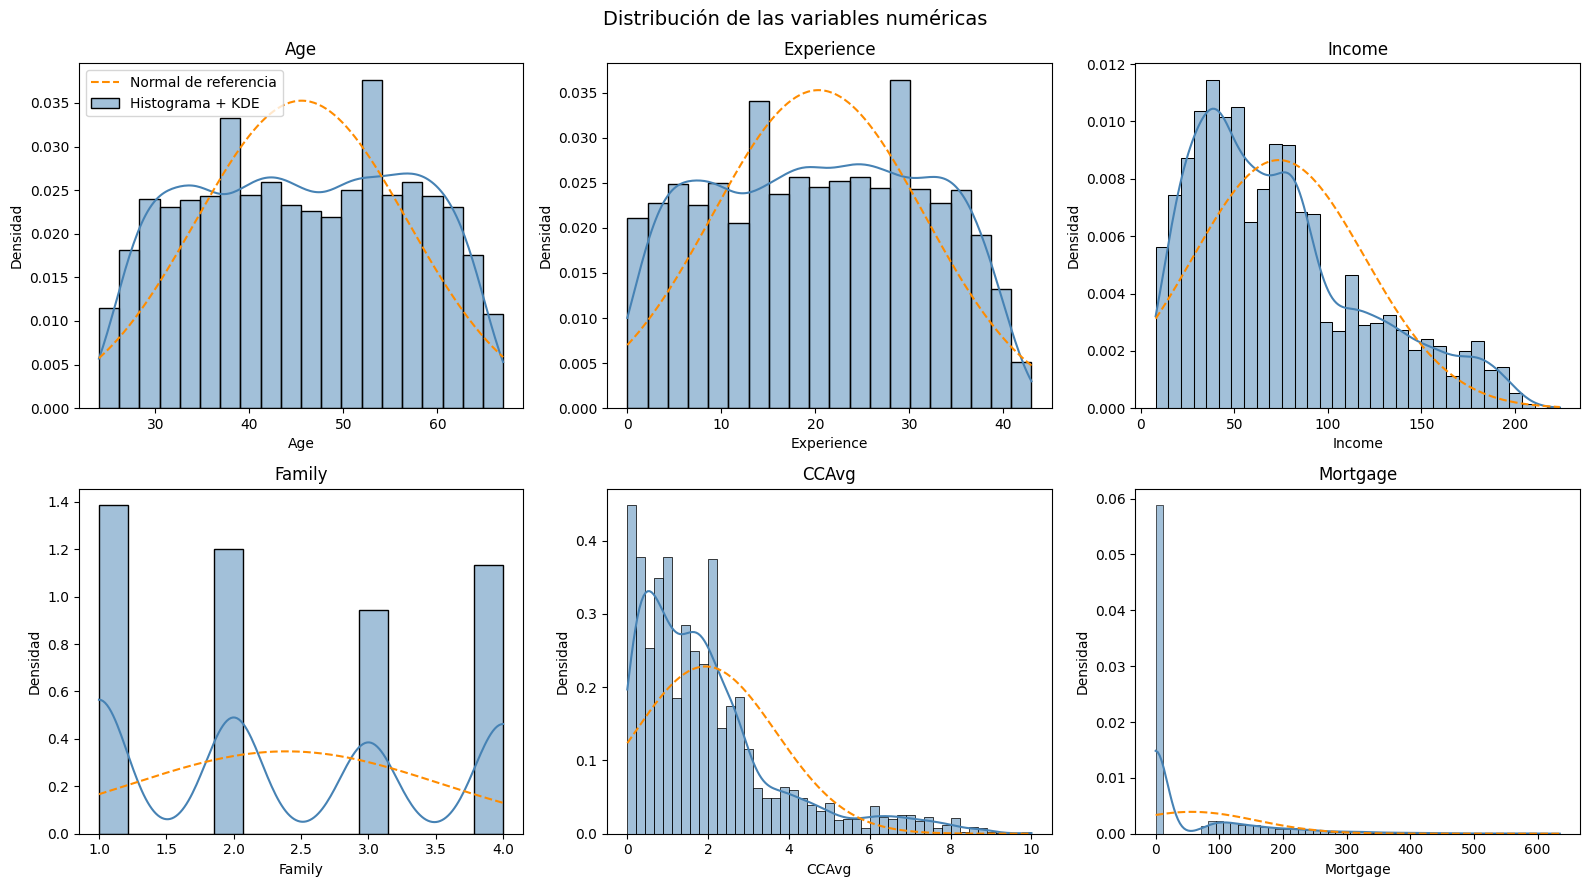

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    datos = loan_df[col]
    sns.histplot(datos, kde=True, stat='density', color='steelblue', ax=ax, label='Histograma + KDE')
    x = np.linspace(datos.min(), datos.max(), 200)
    ax.plot(x, norm.pdf(x, datos.mean(), datos.std()), color='darkorange', linestyle='--', label='Normal de referencia')
    ax.set_title(col)
    ax.set_ylabel('Densidad')
axes.flat[0].legend()
fig.suptitle('Distribución de las variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

**Respuesta:** La forma de los histogramas coincide con los valores de asimetría y curtosis calculados:

* **Age:** el histograma es aproximadamente simétrico y su curva KDE es casi plana entre los 30 y los 60 años, más ancha y baja que la curva normal de referencia. Esto confirma una distribución **simétrica** (asimetría ≈ 0) y **platicúrtica** (curtosis = −1.16).
* **Income:** la mayor concentración de clientes está entre 30 y 50 mil USD y la distribución se extiende con una cola hacia la derecha hasta más de 200 mil USD, lo que confirma la **asimetría positiva moderada** (0.84). Su curtosis cercana a 0 se refleja en colas similares a las de la normal.
* **Mortgage:** se observa un pico muy pronunciado en 0 (clientes sin hipoteca) y una cola larga y aplanada hacia la derecha. Su forma está muy lejos de la curva normal, lo que coincide con la **asimetría positiva fuerte** (2.10) y la distribución **leptocúrtica** (4.76).

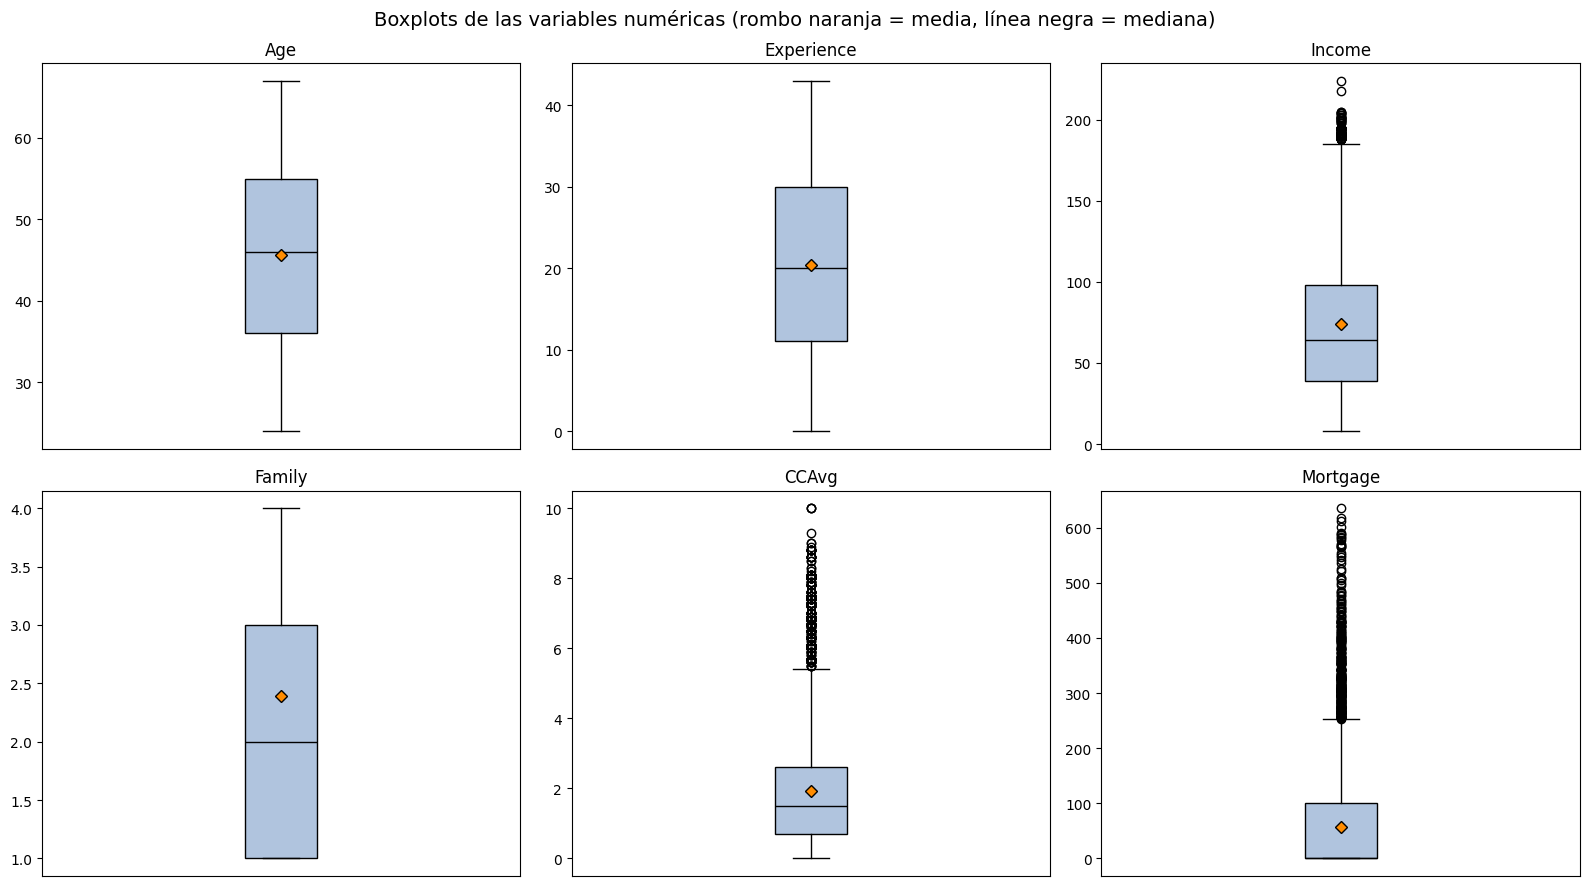

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(loan_df[col], showmeans=True, patch_artist=True,
               boxprops={'facecolor': 'lightsteelblue'},
               medianprops={'color': 'black'},
               meanprops={'marker': 'D', 'markerfacecolor': 'darkorange', 'markeredgecolor': 'black'})
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle('Boxplots de las variables numéricas (rombo naranja = media, línea negra = mediana)', fontsize=14)
plt.tight_layout()
plt.show()

**Respuesta:** La posición de la media respecto a la mediana indica el sesgo de la distribución, ya que la media es sensible a los valores extremos y la mediana no:

* **Age** (media 45.6, mediana 46) y **Experience** (media 20.3, mediana 20): la media prácticamente coincide con la mediana, lo que indica distribuciones **simétricas**, sin valores atípicos.
* **Income** (media 73.8, mediana 64), **CCAvg** (media 1.9, mediana 1.5) y **Family** (media 2.4, mediana 2): la media se ubica por encima de la mediana, lo que indica **asimetría positiva** (cola hacia la derecha). En Income y CCAvg, los valores atípicos altos (círculos sobre el bigote superior) jalan la media hacia arriba.
* **Mortgage** (media 56.7, mediana 0): es el caso más extremo. La mediana es 0 (coincide con el borde inferior de la caja, por eso no se distingue la línea), mientras que la media es mucho mayor debido a los numerosos valores atípicos de hasta 635 mil USD. Esto indica una **asimetría positiva fuerte**.

Estas observaciones coinciden con los coeficientes de asimetría calculados en el ejercicio 6.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [43]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


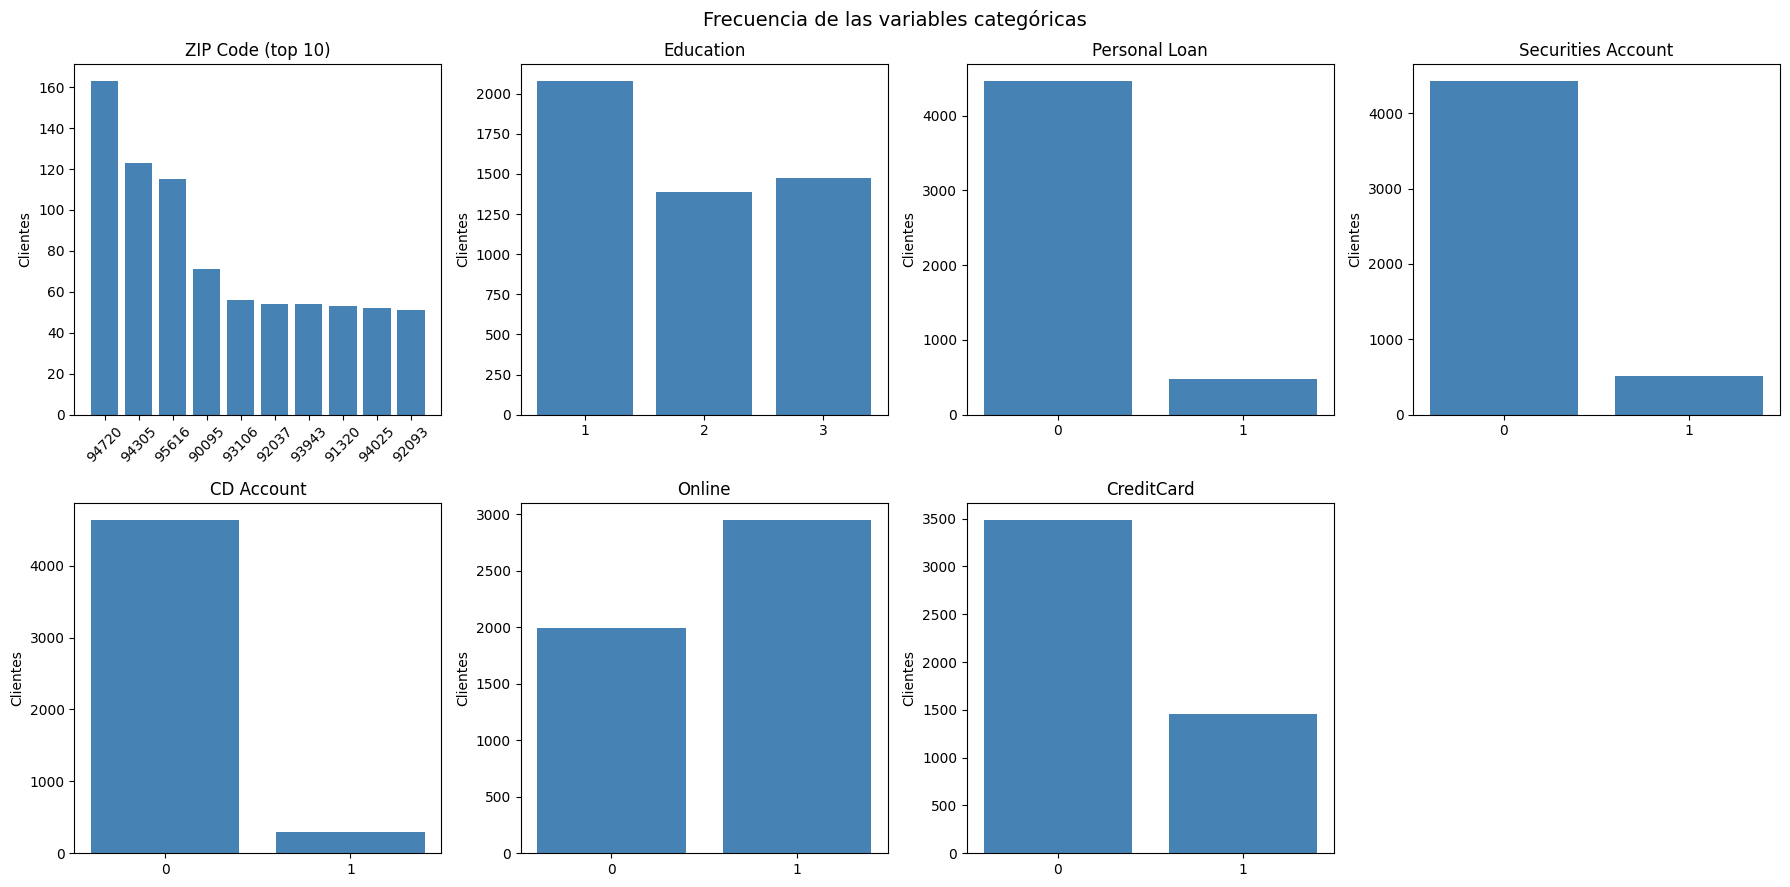

In [44]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    conteo = loan_df[col].value_counts()
    if col == 'ZIP Code':
        conteo = conteo.head(10)
    else:
        conteo = conteo.sort_index()
    ax.bar(conteo.index.astype(str), conteo.values, color='steelblue')
    ax.set_title(col if col != 'ZIP Code' else 'ZIP Code (top 10)')
    ax.set_ylabel('Clientes')
    ax.tick_params(axis='x', rotation=45 if col == 'ZIP Code' else 0)
axes.flat[-1].axis('off')
fig.suptitle('Frecuencia de las variables categóricas', fontsize=14)
plt.tight_layout()
plt.show()

**Respuesta:**

* **ZIP Code:** tiene alta cardinalidad (467 códigos distintos), por lo que solo se graficaron los 10 más frecuentes. El más común (94720) agrupa apenas 163 clientes (3.3%), lo que indica que los clientes están muy dispersos geográficamente.
* **Education:** el nivel más frecuente es graduado (1) con 42.1%, mientras que universitario (2) y posgrado (3) tienen proporciones similares (28.0% y 29.9%).
* **Personal Loan:** la variable de salida está **desbalanceada**: solo el 9.7% de los clientes aceptó el préstamo personal. Esto deberá considerarse al construir el modelo predictivo.
* **Productos bancarios:** la mayoría de los clientes no cuenta con cuenta de valores (89.6%), certificado de depósito (93.9%) ni tarjeta de crédito del banco (70.6%). En cambio, la banca en línea es el único servicio utilizado por la mayoría (59.7%).

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

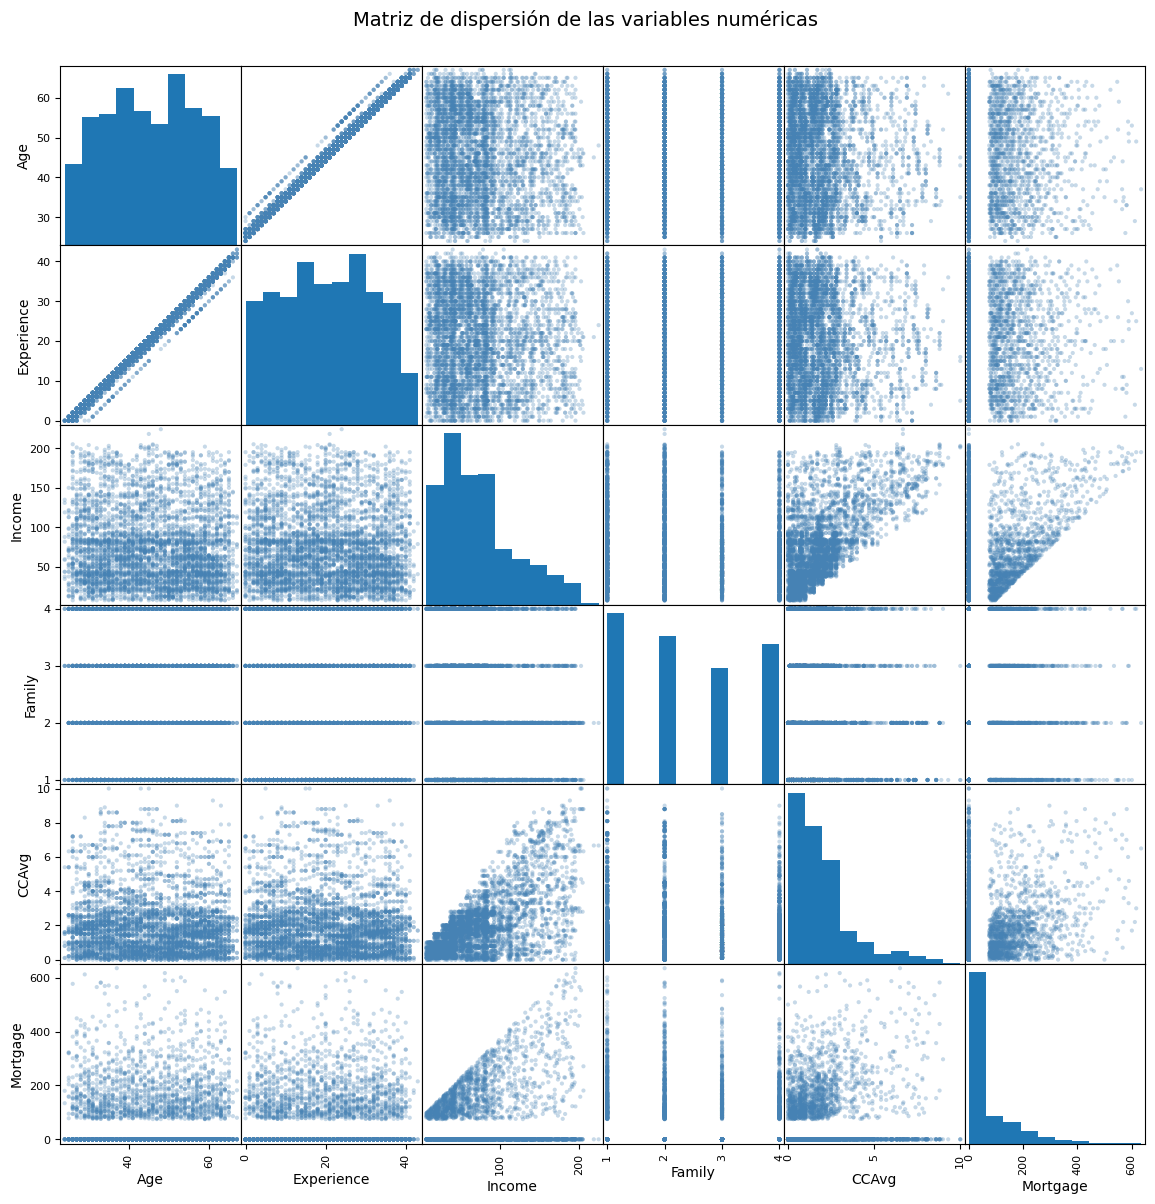

In [45]:
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(14, 14), alpha=0.3, diagonal='hist', color='steelblue')
plt.suptitle('Matriz de dispersión de las variables numéricas', fontsize=14, y=0.92)
plt.show()

**Respuesta:** Se seleccionó el par **Income – CCAvg**. En su gráfico de dispersión se observa una **tendencia positiva**: a mayor ingreso anual, mayor gasto mensual con tarjeta de crédito. La nube tiene forma de cuña o abanico: los clientes con ingresos bajos (menos de 50 mil USD) concentran gastos bajos, mientras que en ingresos altos la dispersión aumenta considerablemente, es decir, hay clientes de altos ingresos que gastan mucho y otros que gastan poco. Además, se observa un límite superior diagonal: prácticamente no existen clientes con ingresos bajos y gastos altos, lo cual es lógico, ya que el gasto está limitado por el ingreso.

Otras relaciones evidentes en la matriz son **Age – Experience**, que forman casi una línea recta (relación lineal muy fuerte), e **Income – Mortgage**, que presenta un patrón similar de cuña. El resto de los pares no muestran una tendencia clara.

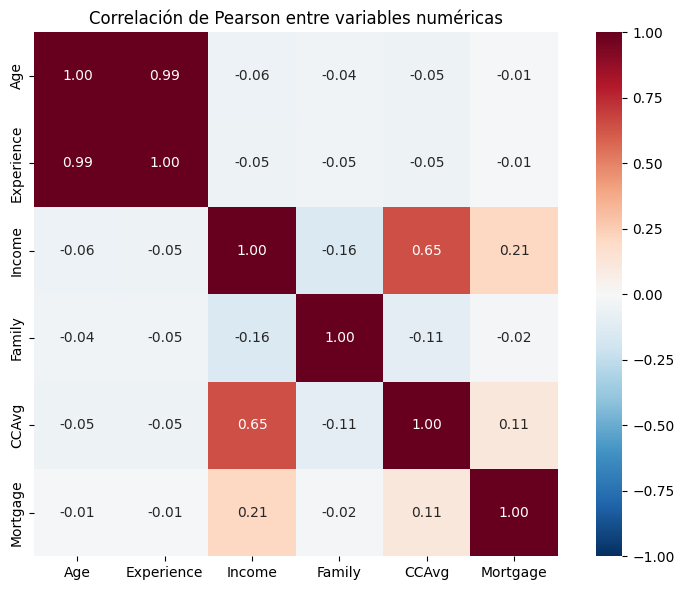

In [46]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Correlación de Pearson entre variables numéricas')
plt.tight_layout()
plt.show()

**Respuesta:** Sí, el valor numérico se corresponde con lo esperado. La correlación de Pearson entre **Income y CCAvg es 0.65**, una relación **positiva moderada a fuerte**: confirma la tendencia ascendente observada, pero no llega a valores cercanos a 1 porque los puntos no forman una línea recta, sino una nube que se dispersa conforme aumenta el ingreso.

Como comparación, **Age y Experience** presentan una correlación de **0.99**, coherente con la línea casi perfecta de su gráfico de dispersión, ya que ambas variables crecen juntas con el paso del tiempo. Por su parte, **Income y Mortgage** muestran una correlación positiva débil (0.21), y el resto de los pares tienen valores cercanos a 0, lo que indica que no existe una relación lineal entre ellos.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


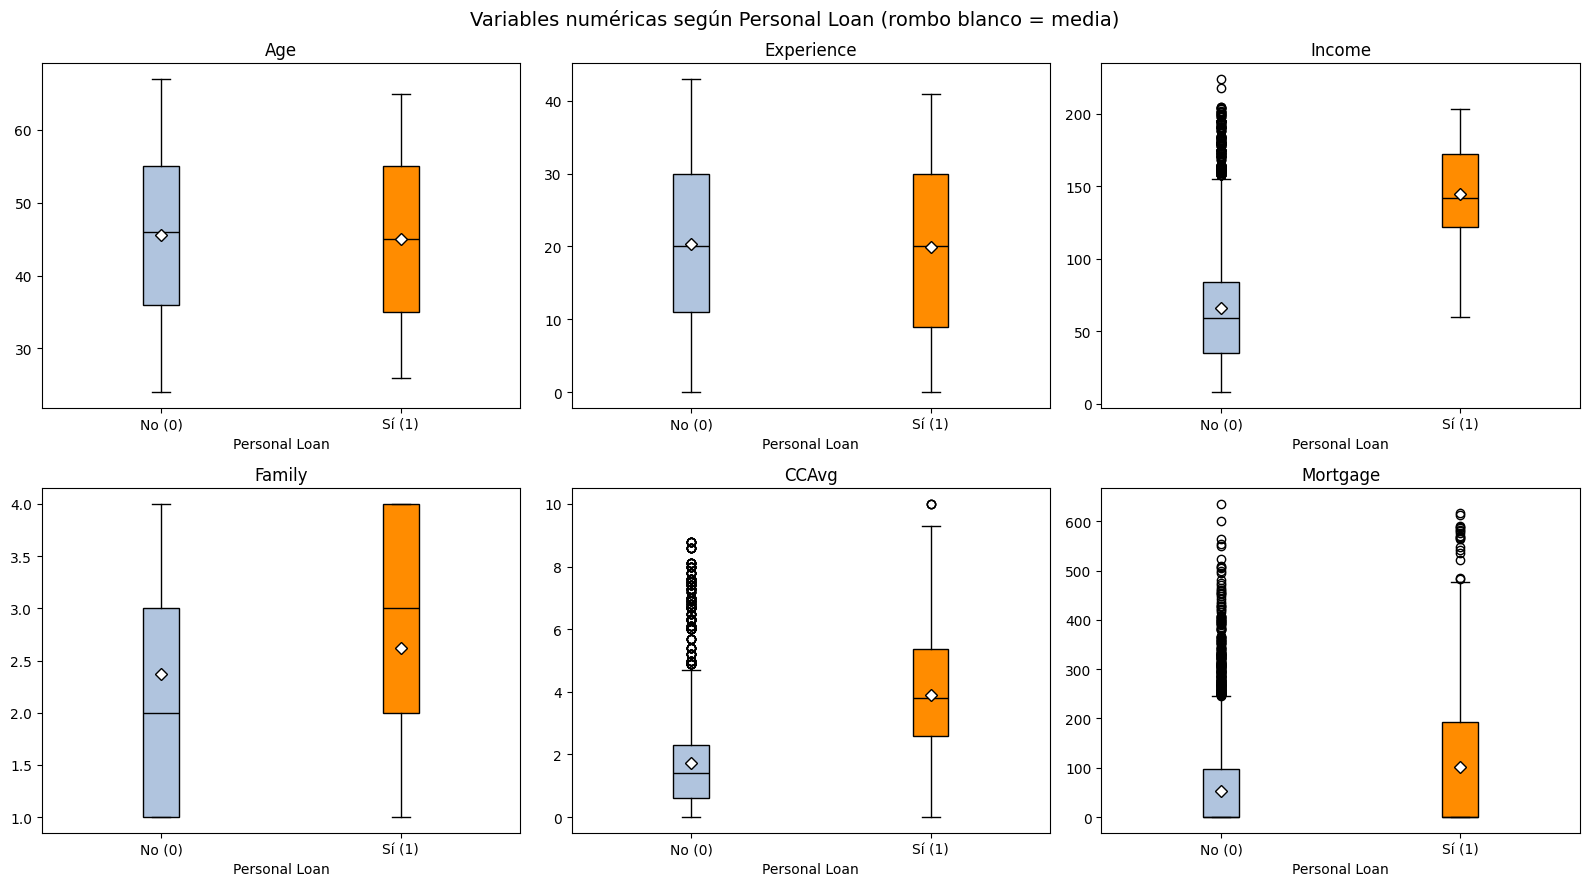

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    grupos = [loan_df.loc[loan_df['Personal Loan'] == v, col] for v in ['0', '1']]
    cajas = ax.boxplot(grupos, tick_labels=['No (0)', 'Sí (1)'], showmeans=True, patch_artist=True,
                       medianprops={'color': 'black'},
                       meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
    for caja, color in zip(cajas['boxes'], ['lightsteelblue', 'darkorange']):
        caja.set_facecolor(color)
    ax.set_title(col)
    ax.set_xlabel('Personal Loan')
fig.suptitle('Variables numéricas según Personal Loan (rombo blanco = media)', fontsize=14)
plt.tight_layout()
plt.show()

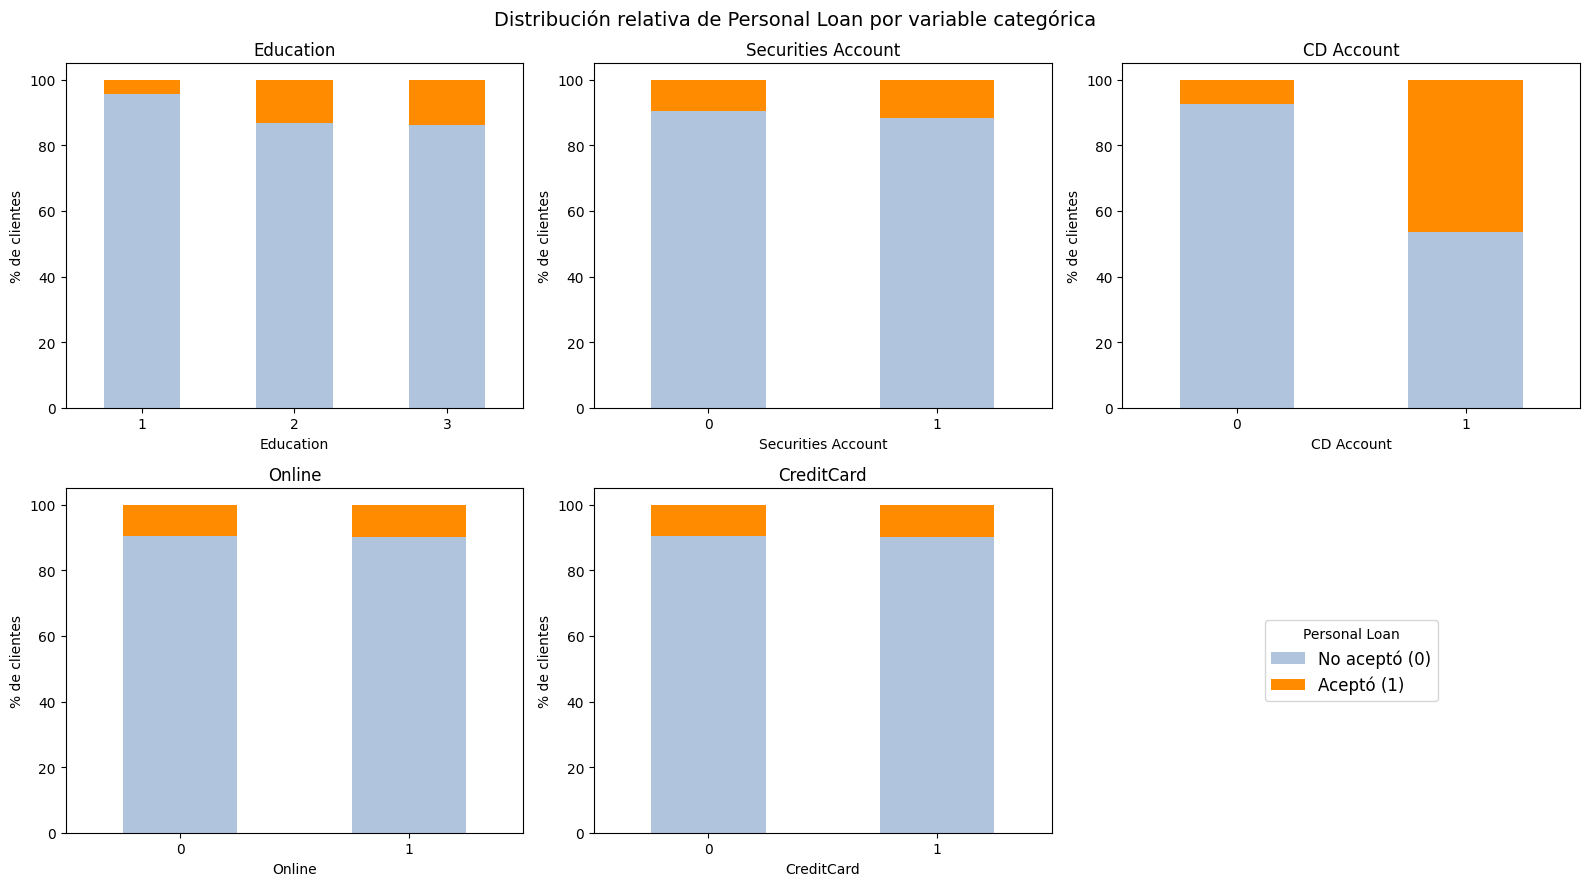

In [48]:
cats = [c for c in cat_cols if c not in ['ZIP Code', 'Personal Loan']]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cats):
    tabla = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index') * 100
    tabla.plot(kind='bar', stacked=True, color=['lightsteelblue', 'darkorange'], ax=ax, legend=False, rot=0)
    ax.set_title(col)
    ax.set_ylabel('% de clientes')
handles, _ = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, ['No aceptó (0)', 'Aceptó (1)'], title='Personal Loan', loc='center', fontsize=12)
axes.flat[-1].axis('off')
fig.suptitle('Distribución relativa de Personal Loan por variable categórica', fontsize=14)
plt.tight_layout()
plt.show()

**Respuesta:**

**Variables numéricas:**

* **Income** es la variable que mejor distingue a quienes aceptan el préstamo: la mediana de ingreso de los clientes que aceptaron es de 142 mil USD, frente a 59 mil USD de quienes no aceptaron, y sus cajas prácticamente no se traslapan. Es decir, el préstamo personal es aceptado principalmente por clientes de ingresos altos.
* **CCAvg** muestra un patrón similar: quienes aceptaron gastan en promedio más con tarjeta de crédito (mediana de 3.8 mil USD mensuales frente a 1.4 mil USD). Esto es coherente con la correlación de 0.65 entre Income y CCAvg observada en el ejercicio 9.
* **Family** y **Mortgage** presentan diferencias menores (familias ligeramente más grandes y montos de hipoteca más altos entre quienes aceptaron), mientras que **Age** y **Experience** tienen distribuciones prácticamente idénticas en ambos grupos, por lo que no parecen influir en la aceptación.

**Variables categóricas:**

* **CD Account** es la variable categórica con mayor relación con la aceptación: el 46.5% de los clientes que tienen certificado de depósito aceptó el préstamo, frente a solo 7.3% de quienes no lo tienen.
* **Education** también muestra una relación: la tasa de aceptación es de 4.5% en clientes graduados (1), y sube a 13.1% en universitarios (2) y 13.9% en posgrado (3).
* **Securities Account**, **Online** y **CreditCard** presentan proporciones casi iguales de aceptación en ambas categorías (alrededor de 10%), por lo que no parecen estar relacionadas con la decisión de aceptar el préstamo.

**Conclusión:** el perfil del cliente con mayor probabilidad de aceptar un préstamo personal es el de ingresos altos, mayor gasto con tarjeta de crédito, nivel educativo universitario o superior y con certificado de depósito. Estas variables serán las más relevantes para el modelo predictivo.

---

**Declaración de uso de IA**

Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande], utilizado como tutor paso a paso: explicación de conceptos de limpieza de datos, estadística descriptiva, sugerencia de código, depuración de errores y apoyo en la redacción e interpretación de resultados. El código fue ejecutado y verificado por mi. https://claude.ai/

---